# 04 — Évaluation et comparaison des deux versions du LLM
Étape 3 de l'énoncé : classer **le même ensemble de test** avec le LLM non personnalisé et le LLM personnalisé, puis calculer le **F1 par classe** et le **F1 pondéré** (seuil attendu : ≥ 92 % pour le LLM personnalisé).

Le test (120 tickets, stratifié) n'a servi ni à choisir le modèle, ni les hyperparamètres, ni les prompts.

In [1]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
from classif import config, data, prompts, evaluation
config.RESULTS_DIR.mkdir(exist_ok=True)
import torch
from classif import hf_model
train, val, test = data.load_splits()
trval = pd.concat([train, val])
print(len(test), "tickets de test ;", test.queue.nunique(), "classes")
L = prompts.labels()
preds = {}

120 tickets de test ; 10 classes


## 1. Version non personnalisée : `Qwen/Qwen3-8B` sans adaptateur

In [2]:
tok = hf_model.load_tokenizer()
base = hf_model.load_model()
sc_base = hf_model.score(base, tok, test)
preds["Qwen3-8B (sans personnalisation)"] = hf_model.predict(sc_base)
preds["Qwen3-8B sans personnalisation, prompt compact"] = hf_model.predict(hf_model.score(base, tok, test, compact=True))
# contrôle du format : génération libre gloutonne, sans contrainte
gen = hf_model.generate(base, tok, test)
ok = [g in L for g in gen]
print(f"génération libre : {np.mean(ok):.1%} de sorties exactement dans la liste des files")
print("exemples hors liste :", [g for g, o in zip(gen, ok) if not o][:5])
pred_libre = [g if g in L else "(hors liste)" for g in gen]
print("F1 pondéré (génération libre, hors liste = erreur) :", round(evaluation.weighted_f1(test.queue, pred_libre), 3))
del base; torch.cuda.empty_cache()

génération libre : 100.0% de sorties exactement dans la liste des files
exemples hors liste : []


F1 pondéré (génération libre, hors liste = erreur) : 0.468


## 2. Version personnalisée : `Qwen3-8B` + adaptateur LoRA (3 entraînements)
La graine 0 est le modèle de référence désigné avant l'évaluation ; les graines 1 et 2 mesurent la variabilité.

In [3]:
base = hf_model.load_model()
from peft import PeftModel
res_seeds, scores_ft = {}, {}
model = None
for seed in (0, 1, 2):
    path = config.MODELS_DIR / f"lora_seed{seed}"
    model = PeftModel.from_pretrained(base, str(path), adapter_name=f"s{seed}") if model is None else model
    if seed: model.load_adapter(str(path), adapter_name=f"s{seed}")
    model.set_adapter(f"s{seed}"); model.eval()
    sc = hf_model.score(model, tok, test, compact=True)
    scores_ft[seed] = sc
    res_seeds[seed] = hf_model.predict(sc)
    if seed == 0:
        gen_ft = hf_model.generate(model, tok, test, compact=True)
f1s = {s: evaluation.weighted_f1(test.queue, p) for s, p in res_seeds.items()}
print("F1 pondéré par graine :", {s: round(v, 4) for s, v in f1s.items()}, "| moyenne", round(np.mean(list(f1s.values())), 4), "± ecart-type", round(np.std(list(f1s.values())), 4))
okft = [g in L for g in gen_ft]
print(f"génération libre (graine 0) : {np.mean(okft):.1%} de sorties exactement dans la liste ; identique au choix par probabilité : {np.mean([g == p for g, p in zip(gen_ft, res_seeds[0])]):.1%}")
preds["Qwen3-8B + LoRA (personnalisé)"] = res_seeds[0]
del model, base; torch.cuda.empty_cache()

F1 pondéré par graine : {0: 0.9329, 1: 0.908, 2: 0.9164} | moyenne 0.9191 ± ecart-type 0.0103
génération libre (graine 0) : 100.0% de sorties exactement dans la liste ; identique au choix par probabilité : 100.0%


## 3. Points de comparaison supplémentaires (pour situer les scores)

In [4]:
from classif import vllm_client
ref_name = "Qwen3.8-27B (vLLM, sans personnalisation)"
p27 = vllm_client.classify(test, guided=True)
preds[ref_name] = p27
print(ref_name, "— sorties dans la liste :", np.mean([p in L for p in p27]))

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
mk = lambda d: d.business_type + " | " + d.language + " | " + d.subject + "\n" + d.body
clf = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True), LogisticRegression(C=30, max_iter=3000))
clf.fit(mk(trval), trval.queue)
preds["TF-IDF + régression logistique (sans LLM)"] = clf.predict(mk(test)).tolist()

# plus proche voisin dans l'espace d'embeddings multilingue bge-m3 (sans LLM, sans entraînement) : mesure l'effet des « jumeaux »
from sentence_transformers import SentenceTransformer
enc = SentenceTransformer("BAAI/bge-m3", device="cuda")
emb = lambda d: enc.encode((d.subject + "\n" + d.body).tolist(), batch_size=32, normalize_embeddings=True, show_progress_bar=False)
Et, Ea = emb(test), emb(trval)
del enc; torch.cuda.empty_cache()
S_ta = Et @ Ea.T
simmax = S_ta.max(1)
preds["1 plus proche voisin bge-m3 (sans LLM)"] = trval.queue.values[S_ta.argmax(1)].tolist()

Qwen3.8-27B (vLLM, sans personnalisation) — sorties dans la liste : 1.0


## 4. Résultat demandé : F1 par classe et F1 pondéré, deux versions du LLM, même test

,Qwen3-8B (sans personnalisation),"Qwen3-8B sans personnalisation, prompt compact",Qwen3-8B + LoRA (personnalisé),"Qwen3.8-27B (vLLM, sans personnalisation)",TF-IDF + régression logistique (sans LLM),1 plus proche voisin bge-m3 (sans LLM),support
classe,,,,,,,
Billing and Payments,0.941,0.875,1.000,0.941,0.875,1.000,9.0
Customer Service,0.000,0.000,0.938,0.000,0.462,1.000,17.0
General Inquiry,0.000,0.000,1.000,0.000,1.000,1.000,1.0
Human Resources,0.000,0.000,1.000,0.000,0.800,1.000,3.0
IT Support,0.194,0.296,0.903,0.286,0.733,0.938,15.0
Product Support,0.432,0.406,0.895,0.167,0.500,0.974,19.0
Returns and Exchanges,0.889,0.889,0.941,0.800,0.615,1.000,8.0
Sales and Pre-Sales,0.000,0.000,1.000,0.571,0.500,1.000,3.0
Service Outages and Maintenance,0.857,0.800,0.800,0.750,0.500,1.000,3.0


,version,F1 pondéré,IC95 % bootstrap,exactitude
0,Qwen3-8B (sans personnalisation),0.4706,[0.380 ; 0.572],0.5333
1,"Qwen3-8B sans personnalisation, prompt compact",0.3911,[0.305 ; 0.483],0.4167
2,Qwen3-8B + LoRA (personnalisé),0.9329,[0.884 ; 0.975],0.9333
3,"Qwen3.8-27B (vLLM, sans personnalisation)",0.4260,[0.333 ; 0.532],0.5083
4,TF-IDF + régression logistique (sans LLM),0.6360,[0.540 ; 0.714],0.6500
5,1 plus proche voisin bge-m3 (sans LLM),0.9752,[0.943 ; 1.000],0.9750


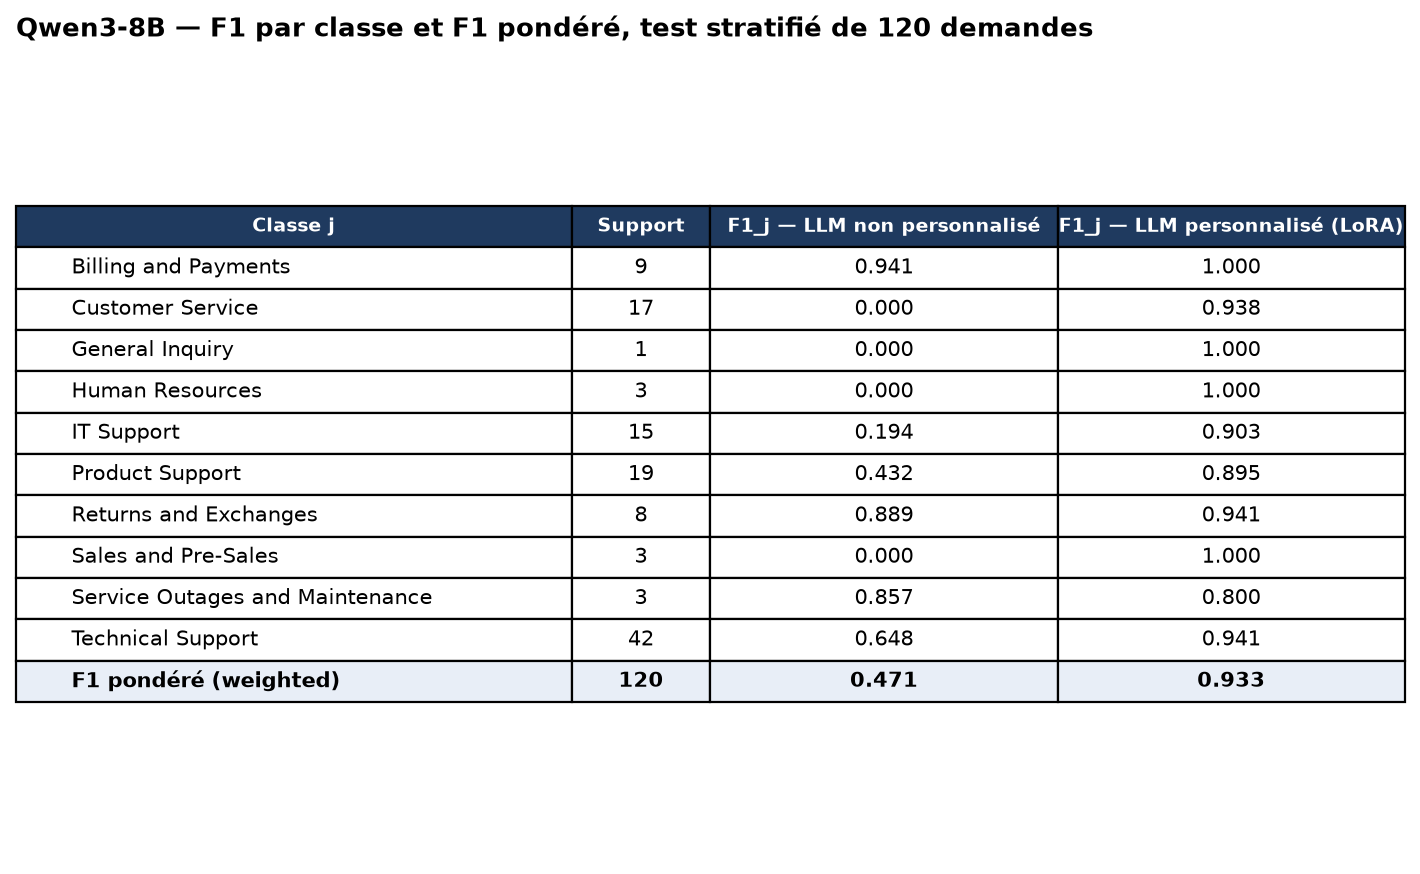


F1 pondéré du LLM personnalisé : 0.9329 — seuil 0,92 : ATTEINT


In [5]:
A, B = "Qwen3-8B (sans personnalisation)", "Qwen3-8B + LoRA (personnalisé)"
rep = {n: evaluation.f1_by_class(test.queue, p) for n, p in preds.items()}
tableau = pd.DataFrame({n: r["F1"] for n, r in rep.items()})
tableau["support"] = rep[A]["support"]
tableau.loc["F1 PONDÉRÉ"] = [r.attrs["weighted_f1"] for r in rep.values()] + [int(rep[A]["support"].sum())]
display(tableau.round(3))
tableau.to_csv(config.RESULTS_DIR / "f1_par_classe.csv")
resume = []
for n, p in preds.items():
    lo, hi = evaluation.bootstrap_ci(test.queue, p)
    resume.append({"version": n, "F1 pondéré": round(rep[n].attrs["weighted_f1"], 4), "IC95 % bootstrap": f"[{lo:.3f} ; {hi:.3f}]",
                   "exactitude": round(float(np.mean(np.array(p) == test.queue.values)), 4)})
resume = pd.DataFrame(resume); display(resume); resume.to_csv(config.RESULTS_DIR / "synthese_comparaison.csv", index=False)
evaluation.capture_png({"LLM non personnalisé": rep[A], "LLM personnalisé (LoRA)": rep[B]}, config.RESULTS_DIR / "capture_f1_scores.png",
                       title="Qwen3-8B — F1 par classe et F1 pondéré, test stratifié de 120 demandes")
from IPython.display import Image; display(Image(str(config.RESULTS_DIR / "capture_f1_scores.png")))
v = rep[B].attrs["weighted_f1"]
print(f"\nF1 pondéré du LLM personnalisé : {v:.4f} — seuil 0,92 : {'ATTEINT' if v >= 0.92 else 'NON ATTEINT'}")

### Détail par classe (précision, rappel, F1, comptes) pour les deux versions

In [6]:
for n in (A, B):
    print("=====", n); display(rep[n].round(3))
pd.concat({A: rep[A], B: rep[B]}).to_csv(config.RESULTS_DIR / "detail_par_classe.csv")

===== Qwen3-8B (sans personnalisation)


,support,TP,FP,FN,precision,rappel,F1
classe,,,,,,,
Billing and Payments,9,8,0,1,1.000,0.889,0.941
Customer Service,17,0,1,17,0.000,0.000,0.000
General Inquiry,1,0,0,1,0.000,0.000,0.000
Human Resources,3,0,0,3,0.000,0.000,0.000
IT Support,15,3,13,12,0.188,0.200,0.194
Product Support,19,8,10,11,0.444,0.421,0.432
Returns and Exchanges,8,8,2,0,0.800,1.000,0.889
Sales and Pre-Sales,3,0,0,3,0.000,0.000,0.000
Service Outages and Maintenance,3,3,1,0,0.750,1.000,0.857


===== Qwen3-8B + LoRA (personnalisé)


,support,TP,FP,FN,precision,rappel,F1
classe,,,,,,,
Billing and Payments,9,9,0,0,1.000,1.000,1.000
Customer Service,17,15,0,2,1.000,0.882,0.938
General Inquiry,1,1,0,0,1.000,1.000,1.000
Human Resources,3,3,0,0,1.000,1.000,1.000
IT Support,15,14,2,1,0.875,0.933,0.903
Product Support,19,17,2,2,0.895,0.895,0.895
Returns and Exchanges,8,8,1,0,0.889,1.000,0.941
Sales and Pre-Sales,3,3,0,0,1.000,1.000,1.000
Service Outages and Maintenance,3,2,0,1,1.000,0.667,0.800


## 5. Matrices de confusion et erreurs du modèle personnalisé

In [7]:
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, n in zip(axs, (A, B)):
    cm = evaluation.confusion(test.queue, preds[n]).values
    ax.imshow(cm, cmap="Blues"); ax.set_title(n, fontsize=10)
    ax.set_xticks(range(10)); ax.set_xticklabels([l[:14] for l in L], rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(10)); ax.set_yticklabels([l[:14] for l in L], fontsize=7)
    for i in range(10):
        for j in range(10):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("file prédite"); ax.set_ylabel("file réelle")
plt.tight_layout(); plt.savefig(config.RESULTS_DIR / "matrices_confusion.png", dpi=140); plt.show()

In [8]:
err = test.assign(prediction=preds[B])
err = err[err.queue != err.prediction][["queue", "prediction", "language", "business_type", "subject"]]
print(len(err), "erreurs sur", len(test)); display(err)
err.to_csv(config.RESULTS_DIR / "erreurs_modele_personnalise.csv")
pd.DataFrame({"ticket": test.index, "queue": test.queue.values, **{n: p for n, p in preds.items()}}).to_csv(config.RESULTS_DIR / "predictions_test.csv", index=False)

8 erreurs sur 120


,queue,prediction,language,business_type,subject
ticket,,,,,
40,Technical Support,IT Support,en,IT Services,Urgent: Repeated Cisco Router ISR4331 Reboots
55,Product Support,Technical Support,en,Tech Online Store,Issue with Dell XPS 13 9310
140,Service Outages and Maintenance,IT Support,pt,IT Services,Implantação Urgente de Servidores Durante a Queda do AWS
234,IT Support,Technical Support,pt,IT Services,Urgente: Mau Funcionamento de Hardware no Dell XPS 13 9310
276,Technical Support,Product Support,de,Tech Online Store,Surface Pro 7 Problem
355,Customer Service,Product Support,en,IT Services,Surface Pro 7 Touchscreen Issues
364,Customer Service,Returns and Exchanges,pt,Tech Online Store,MacBook Air M1 com defeito
475,Product Support,Technical Support,fr,Tech Online Store,Problème avec le Dell XPS 13 9310


## 6. Stabilité : trois entraînements et F1 par langue
Les 3 graines sont rapportées en entier. Le F1 par langue vérifie que le modèle n'est pas bon dans une langue seulement.

In [9]:
st = pd.DataFrame([{"graine": s, "F1 pondéré": round(f1s[s], 4), "exactitude": round(float(np.mean(np.array(p) == test.queue.values)), 4)} for s, p in res_seeds.items()])
display(st)
lang = test.assign(base=preds[A], perso=preds[B]).groupby("language").apply(
    lambda g: pd.Series({"tickets": len(g), "F1 pondéré non personnalisé": evaluation.weighted_f1(g.queue, g.base), "F1 pondéré personnalisé": evaluation.weighted_f1(g.queue, g.perso)}))
display(lang.round(3)); lang.to_csv(config.RESULTS_DIR / "f1_par_langue.csv")
st.to_csv(config.RESULTS_DIR / "stabilite_graines.csv", index=False)

,graine,F1 pondéré,exactitude
0,0,0.9329,0.9333
1,1,0.9080,0.9083
2,2,0.9164,0.9167


,tickets,F1 pondéré non personnalisé,F1 pondéré personnalisé
language,,,
de,33.0,0.623,0.971
en,37.0,0.404,0.920
es,20.0,0.417,1.000
fr,15.0,0.507,0.937
pt,15.0,0.449,0.748


## 7. Contrôle de fuite : le score tient-il sur des demandes sans « copie » dans l'entraînement ?
Le notebook 01 a montré que beaucoup de tickets ont un quasi-doublon (souvent traduit) de même file. On mesure, pour chaque ticket de test, sa **similarité maximale avec l'ensemble d'entraînement** (`bge-m3`, multilingue), et le F1 du modèle personnalisé selon cette similarité. C'est un diagnostic *a posteriori* : aucun choix de modèle n'en dépend.

In [10]:
d = test.assign(simmax=simmax, base=preds[A], perso=preds[B], nn=preds["1 plus proche voisin bge-m3 (sans LLM)"])
lignes = []
for lo, hi, nom in [(0.0, 0.85, "< 0,85"), (0.85, 0.90, "0,85 – 0,90"), (0.90, 0.95, "0,90 – 0,95"), (0.95, 1.01, "≥ 0,95 (quasi-copie)")]:
    g = d[(d.simmax >= lo) & (d.simmax < hi)]
    if len(g):
        lignes.append({"similarité max avec l'entraînement": nom, "tickets de test": len(g),
                       "exactitude non personnalisé": round((g.base == g.queue).mean(), 3), "exactitude personnalisé": round((g.perso == g.queue).mean(), 3),
                       "exactitude 1-PPV": round((g.nn == g.queue).mean(), 3)})
fuite = pd.DataFrame(lignes); display(fuite); fuite.to_csv(config.RESULTS_DIR / "controle_fuite.csv", index=False)
print("médiane de similarité max test→entraînement :", round(float(np.median(simmax)), 3), "| part des tickets de test à ≥ 0,90 :", round(float((simmax >= 0.9).mean()), 3), "| à ≥ 0,95 :", round(float((simmax >= 0.95).mean()), 3))
inedit = d[d.simmax < 0.90]
if len(inedit) >= 10:
    print(f"Sous-ensemble sans quasi-doublon (similarité < 0,90) : {len(inedit)} tickets — exactitude non personnalisé {(inedit.base == inedit.queue).mean():.3f} | personnalisé {(inedit.perso == inedit.queue).mean():.3f} | 1-PPV {(inedit.nn == inedit.queue).mean():.3f}")

,similarité max avec l'entraînement,tickets de test,exactitude non personnalisé,exactitude personnalisé,exactitude 1-PPV
0,"< 0,85",7,0.571,0.857,1.000
1,"0,85 – 0,90",25,0.400,0.840,0.920
2,"0,90 – 0,95",54,0.648,0.944,0.981
3,"≥ 0,95 (quasi-copie)",34,0.441,1.000,1.000


médiane de similarité max test→entraînement : 0.926 | part des tickets de test à ≥ 0,90 : 0.733 | à ≥ 0,95 : 0.283
Sous-ensemble sans quasi-doublon (similarité < 0,90) : 32 tickets — exactitude non personnalisé 0.438 | personnalisé 0.844 | 1-PPV 0.938


**Lecture.** Le gain du modèle personnalisé n'est pas uniforme : il est maximal quand le test contient une quasi-copie (souvent une traduction) de l'entraînement. Le score demandé par l'énoncé (test tiré au hasard) est donc atteint, mais il mélange *mémorisation de variantes* et *généralisation à des demandes inédites*. Le sous-ensemble sans quasi-doublon donne une idée de la seconde.

## 8. Synthèse

In [11]:
b, p = rep[A].attrs["weighted_f1"], rep[B].attrs["weighted_f1"]
print(f"LLM non personnalisé : F1 pondéré {b:.3f}")
print(f"LLM personnalisé     : F1 pondéré {p:.3f}  (graines 0/1/2 : {', '.join(f'{v:.3f}' for v in f1s.values())})")
print(f"Gain                 : {(p - b) * 100:+.1f} points de F1 pondéré ; exigence ≥ 0,92 pour le modèle de référence (graine 0) : {'atteinte' if p >= 0.92 else 'non atteinte'} ; moyenne des 3 graines : {np.mean(list(f1s.values())):.3f}")

LLM non personnalisé : F1 pondéré 0.471
LLM personnalisé     : F1 pondéré 0.933  (graines 0/1/2 : 0.933, 0.908, 0.916)
Gain                 : +46.2 points de F1 pondéré ; exigence ≥ 0,92 pour le modèle de référence (graine 0) : atteinte ; moyenne des 3 graines : 0.919
